## Project Overview
This project performs comprehensive exploratory data analysis, cleaning, and customer segmentation using K-Means clustering on a Swiggy food delivery dataset. It also builds and compares multiple machine learning regression models (Linear Regression, Decision Trees, and Random Forests) to accurately predict food delivery times.

In [ ]:
import pandas as pd
import numpy as  np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
pd.set_option("display.max_columns",None)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"]=(8,5)
df_raw=pd.read_csv("//content/swiggy dataset.csv")
df=df_raw.copy()
print("Dataset loaded")
print("Rows and columns:",df.shape)
display(df.head())
print(df.head())

Dataset loaded
Rows and columns: (8680, 10)


,ID,Area,City,Restaurant,Price,Avg ratings,Total ratings,Food type,Address,Delivery time
0,211,Koramangala,Bangalore,Tandoor Hut,300.0,4.4,100.0,"Biryani,Chinese,North Indian,South Indian",5Th Block,59
1,221,Koramangala,Bangalore,Tunday Kababi,300.0,4.1,100.0,"Mughlai,Lucknowi",5Th Block,56
2,246,Jogupalya,Bangalore,Kim Lee,650.0,4.4,100.0,Chinese,Double Road,50
3,248,Indiranagar,Bangalore,New Punjabi Hotel,250.0,3.9,500.0,"North Indian,Punjabi,Tandoor,Chinese",80 Feet Road,57
4,249,Indiranagar,Bangalore,Nh8,NaN,4.0,50.0,"Rajasthani,Gujarati,North Indian,Snacks,Desser...",80 Feet Road,63


    ID         Area       City         Restaurant  Price  Avg ratings  Total ratings  \
0  211  Koramangala  Bangalore        Tandoor Hut  300.0          4.4          100.0   
1  221  Koramangala  Bangalore      Tunday Kababi  300.0          4.1          100.0   
2  246    Jogupalya  Bangalore            Kim Lee  650.0          4.4          100.0   
3  248  Indiranagar  Bangalore  New Punjabi Hotel  250.0          3.9          500.0   
4  249  Indiranagar  Bangalore                Nh8    NaN          4.0           50.0   

                                           Food type       Address  Delivery time  
0          Biryani,Chinese,North Indian,South Indian     5Th Block             59  
1                                   Mughlai,Lucknowi     5Th Block             56  
2                                            Chinese   Double Road             50  
3               North Indian,Punjabi,Tandoor,Chinese  80 Feet Road             57  
4  Rajasthani,Gujarati,North Indian,Snacks,Desser..

In [ ]:
display(df.tail())

,ID,Area,City,Restaurant,Price,Avg ratings,Total ratings,Food type,Address,Delivery time
8675,464626,Panjarapole Cross Road,Ahmedabad,Malt Pizza,500.0,2.9,80.0,Pizzas,Navrangpura,40
8676,465835,Rohini,Delhi,Jay Mata Ji Home Kitchen,200.0,2.9,80.0,South Indian,Rohini,28
8677,465872,Rohini,Delhi,Chinese Kitchen King,150.0,2.9,80.0,"Chinese,Snacks,Tandoor",Rohini,58
8678,465990,Rohini,Delhi,Shree Ram Paratha Wala,150.0,2.9,80.0,"North Indian,Indian,Snacks",Rohini,28
8679,466488,Navrangpura,Ahmedabad,Sassy Street,250.0,2.9,80.0,"Chaat,Snacks,Chinese",Navrangpura,44


In [ ]:
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8680 entries, 0 to 8679
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             8680 non-null   int64  
 1   Area           8680 non-null   object 
 2   City           8680 non-null   object 
 3   Restaurant     8680 non-null   object 
 4   Price          8677 non-null   float64
 5   Avg ratings    8680 non-null   float64
 6   Total ratings  8679 non-null   float64
 7   Food type      8680 non-null   object 
 8   Address        8680 non-null   object 
 9   Delivery time  8680 non-null   int64  
dtypes: float64(3), int64(2), object(5)
memory usage: 678.3+ KB


None

In [ ]:
display(df.describe())

,ID,Price,Avg ratings,Total ratings,Delivery time
count,8680.000000,8677.000000,8680.000000,8679.000000,8680.000000
mean,244812.071429,348.386309,3.655104,156.641318,53.967051
std,158671.617188,230.903490,0.647629,391.470095,14.292335
min,211.000000,0.000000,2.000000,20.000000,20.000000
25%,72664.000000,200.000000,2.900000,50.000000,44.000000
50%,283442.000000,300.000000,3.900000,80.000000,53.000000
75%,393425.250000,400.000000,4.200000,100.000000,64.000000
max,466928.000000,2500.000000,5.000000,10000.000000,109.000000


In [ ]:
missing=pd.DataFrame({
    "Missing":df.isnull().sum(),
    "Percent":(df.isnull().mean()*100).round(2)
})
display(missing)
print()
display(missing[missing["Missing"]>0].sort_values("Percent",ascending=False))
print("Exact duplicate rows:",df.duplicated().sum())
print("Repeated Order IDs:",df ["ID"].duplicated().sum())
display(df[df.duplicated(keep=False)].head(10))

,Missing,Percent
ID,0,0.00
Area,0,0.00
City,0,0.00
Restaurant,0,0.00
Price,3,0.03
Avg ratings,0,0.00
Total ratings,1,0.01
Food type,0,0.00
Address,0,0.00
Delivery time,0,0.00


,Missing,Percent
Price,3,0.03
Total ratings,1,0.01


Exact duplicate rows: 0
Repeated Order IDs: 0


,ID,Area,City,Restaurant,Price,Avg ratings,Total ratings,Food type,Address,Delivery time


In [ ]:
for col in ["Area", "Price", "Restaurant", "Avg ratings", "Total ratings"]:
  print("\nvalues in", col)
  display(df[col].value_counts(dropna=False))


values in Area


,count
Area,
Rohini,257
Chembur,208
Kothrud,149
Andheri East,135
Navrangpura,132
...,...
Nava Naroda,1
Lb Nagar,1
Kustia,1



values in Price


,count
Price,
300.0,1775
200.0,1774
250.0,968
400.0,838
500.0,605
...,...
45.0,1
502.0,1
297.0,1



values in Restaurant


,count
Restaurant,
La Pino'Z Pizza,13
Baskin Robbins,10
Nic Natural Ice Creams,10
Subway,10
Kfc,9
...,...
Zaika The Bakers,1
Bangarpet Chats,1
Shree Ram Parotha House,1



values in Avg ratings


,count
Avg ratings,
2.9,3279
4.3,792
4.2,754
4.1,700
4.4,573
4.0,524
3.9,421
4.5,338
3.8,313



values in Total ratings


,count
Total ratings,
80.0,3273
100.0,1986
20.0,1440
50.0,985
500.0,568
1000.0,407
5000.0,14
10000.0,6
NaN,1


In [ ]:
df.isnull().sum()

,0
ID,0
Area,0
City,0
Restaurant,0
Price,3
Avg ratings,0
Total ratings,1
Food type,0
Address,0
Delivery time,0


In [ ]:
(df.isnull().sum() / len(df)) * 100

,0
ID,0.000000
Area,0.000000
City,0.000000
Restaurant,0.000000
Price,0.034562
Avg ratings,0.000000
Total ratings,0.011521
Food type,0.000000
Address,0.000000
Delivery time,0.000000


In [ ]:
df['Price'] = df.groupby('City')['Price'].transform(
    lambda x: x.fillna(x.median())
)

df['Price'] = df['Price'].fillna(df['Price'].median())

In [ ]:
df['Total ratings'] = df['Total ratings'].fillna(
    df['Total ratings'].median()
)

In [ ]:
# Check duplicate records
df.duplicated().sum()

np.int64(0)

In [ ]:
# Remove duplicate records
df.drop_duplicates(inplace=True)

In [ ]:
df.columns = df.columns.str.strip()
text_columns = [
    'Area',
    'City',
    'Restaurant',
    'Food type',
    'Address'
]

for col in text_columns:
    df[col] = df[col].astype('string').str.strip()

In [ ]:
df['ID'] = pd.to_numeric(df['ID'], errors='coerce')

df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

df['Avg ratings'] = pd.to_numeric(
    df['Avg ratings'], errors='coerce'
)

df['Total ratings'] = pd.to_numeric(
    df['Total ratings'], errors='coerce'
)

df['Delivery time'] = pd.to_numeric(
    df['Delivery time'], errors='coerce'
)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8680 entries, 0 to 8679
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             8680 non-null   int64  
 1   Area           8680 non-null   string 
 2   City           8680 non-null   string 
 3   Restaurant     8680 non-null   string 
 4   Price          8680 non-null   float64
 5   Avg ratings    8680 non-null   float64
 6   Total ratings  8680 non-null   float64
 7   Food type      8680 non-null   string 
 8   Address        8680 non-null   string 
 9   Delivery time  8680 non-null   int64  
dtypes: float64(3), int64(2), string(5)
memory usage: 678.3 KB


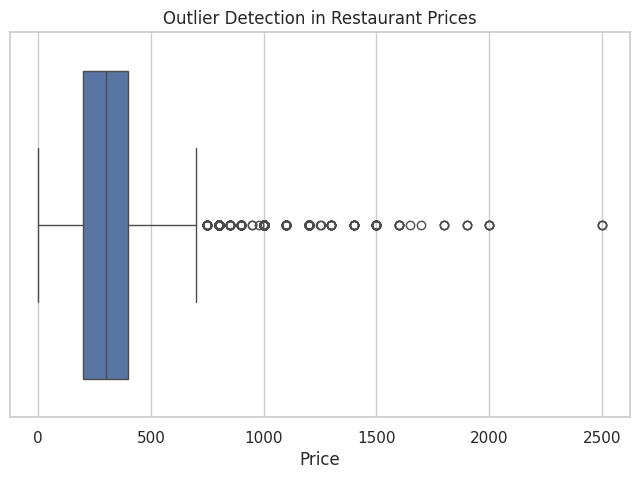

In [ ]:
# Boxplot for price
plt.figure(figsize=(8,5))

sns.boxplot(x=df['Price'])

plt.title('Outlier Detection in Restaurant Prices')
plt.show()

In [ ]:
Q1 = df['Price'].quantile(0.25)

Q3 = df['Price'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['Price'] < lower_limit) |
    (df['Price'] > upper_limit)
]

print("Number of outliers:", len(outliers))

Number of outliers: 582


In [ ]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicates
print("Duplicate Records:", df.duplicated().sum())

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check data types
print("Data Types:")
print(df.dtypes)

# Display cleaned dataset
df.head(10)

Missing Values:
ID               0
Area             0
City             0
Restaurant       0
Price            0
Avg ratings      0
Total ratings    0
Food type        0
Address          0
Delivery time    0
dtype: int64
Duplicate Records: 0
Dataset Shape: (8680, 10)
Data Types:
ID                        int64
Area             string[python]
City             string[python]
Restaurant       string[python]
Price                   float64
Avg ratings             float64
Total ratings           float64
Food type        string[python]
Address          string[python]
Delivery time             int64
dtype: object


,ID,Area,City,Restaurant,Price,Avg ratings,Total ratings,Food type,Address,Delivery time
0,211,Koramangala,Bangalore,Tandoor Hut,300.0,4.4,100.0,"Biryani,Chinese,North Indian,South Indian",5Th Block,59
1,221,Koramangala,Bangalore,Tunday Kababi,300.0,4.1,100.0,"Mughlai,Lucknowi",5Th Block,56
2,246,Jogupalya,Bangalore,Kim Lee,650.0,4.4,100.0,Chinese,Double Road,50
3,248,Indiranagar,Bangalore,New Punjabi Hotel,250.0,3.9,500.0,"North Indian,Punjabi,Tandoor,Chinese",80 Feet Road,57
4,249,Indiranagar,Bangalore,Nh8,300.0,4.0,50.0,"Rajasthani,Gujarati,North Indian,Snacks,Desser...",80 Feet Road,63
5,254,Indiranagar,Bangalore,Treat,800.0,4.5,100.0,"Mughlai,North Indian",100 Feet Road,56
6,258,Indiranagar,Bangalore,Chinita Real Mexican Food,1000.0,4.5,500.0,"Mexican,Beverages,Salads",Double Road,53
7,263,Koramangala,Bangalore,Cupcake Noggins - Cakespastries And Desserts,150.0,4.3,100.0,"Desserts,British,Bakery,Pizzas,Snacks",4Th Block,57
8,267,Domlur,Bangalore,Tea Brew,350.0,4.1,100.0,"American,Italian,Beverages,Continental,Chinese...",Double Road,57
9,308,Koramangala,Bangalore,Bangaliana,300.0,4.0,500.0,Bengali,7Th Block,57


In [ ]:
df.to_csv('Swiggy_Cleaned_Dataset.csv', index=False)

print("Data Cleaning Completed Successfully!")

Data Cleaning Completed Successfully!


In [ ]:
from google.colab import files

files.download('Swiggy_Cleaned_Dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

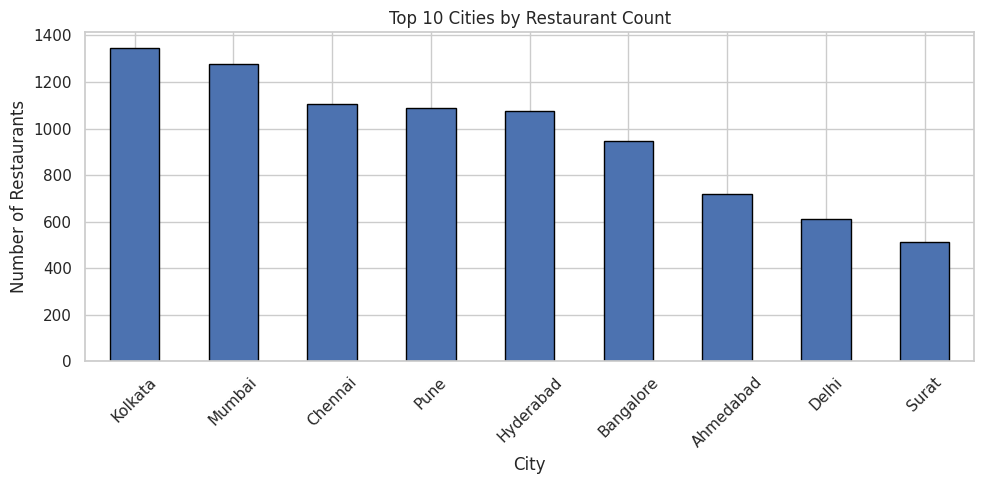

In [ ]:
plt.figure(figsize=(10,5))

df['City'].value_counts().head(10).plot(
    kind='bar', edgecolor='black'
)

plt.title('Top 10 Cities by Restaurant Count')
plt.xlabel('City')
plt.ylabel('Number of Restaurants')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

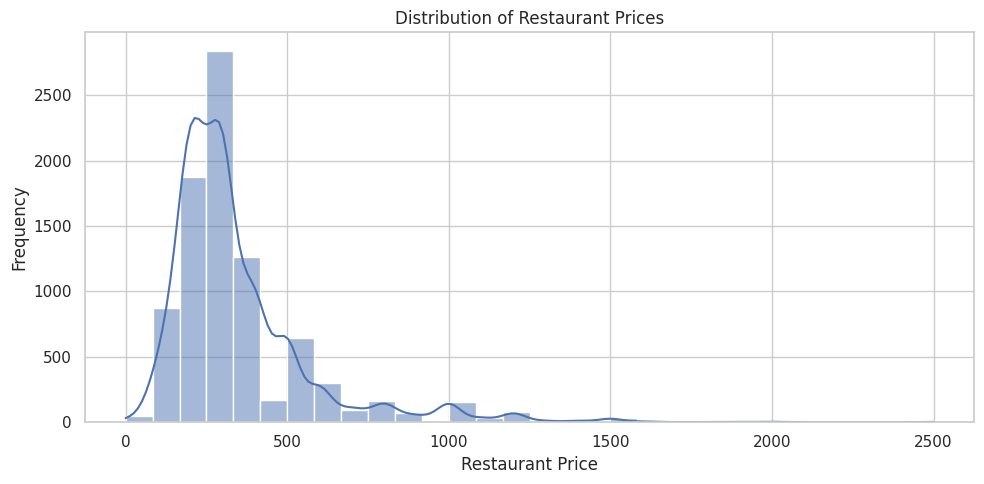

In [ ]:
plt.figure(figsize=(10,5))

sns.histplot(df['Price'].dropna(), bins=30, kde=True)

plt.title('Distribution of Restaurant Prices')
plt.xlabel('Restaurant Price')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

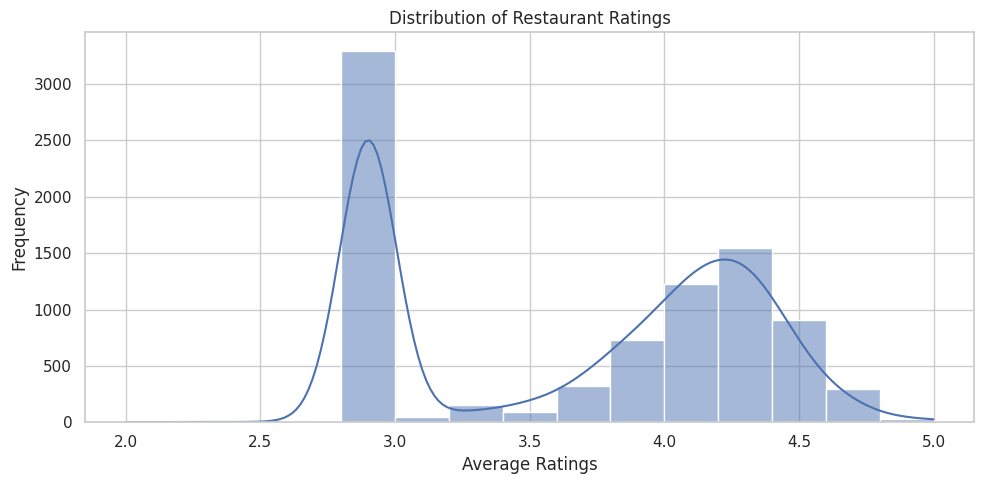

In [ ]:
plt.figure(figsize=(10,5))

sns.histplot(df['Avg ratings'].dropna(), bins=15, kde=True)

plt.title('Distribution of Restaurant Ratings')
plt.xlabel('Average Ratings')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

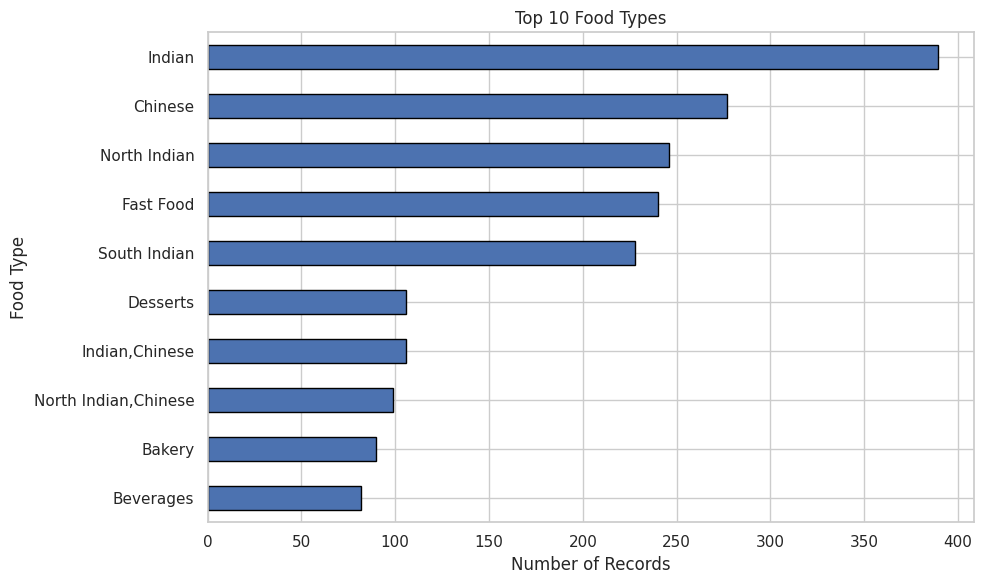

In [ ]:
plt.figure(figsize=(10,6))

df['Food type'].value_counts().head(10).plot(
    kind='barh', edgecolor='black'
)

plt.title('Top 10 Food Types')
plt.xlabel('Number of Records')
plt.ylabel('Food Type')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

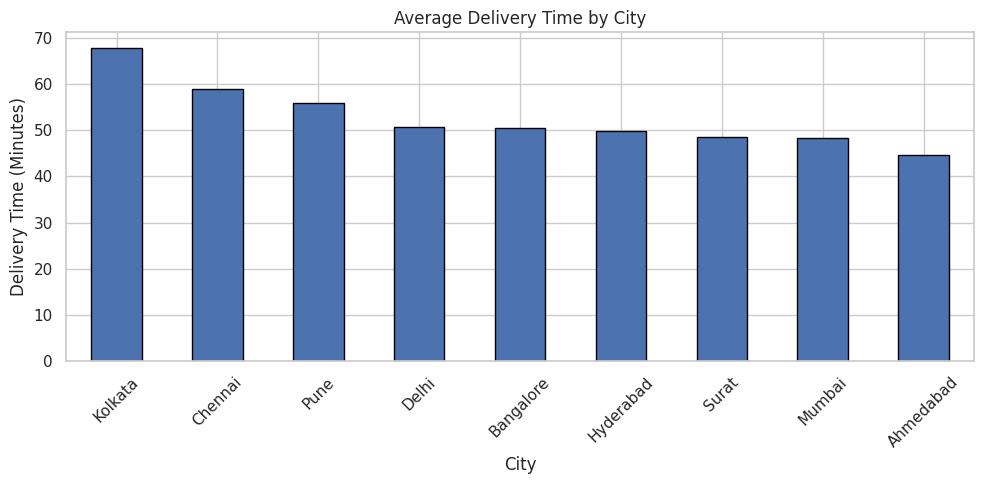

In [ ]:
plt.figure(figsize=(10,5))

city_delivery = df.groupby('City')['Delivery time'].mean().sort_values(ascending=False).head(10)

city_delivery.plot(kind='bar', edgecolor='black')

plt.title('Average Delivery Time by City')
plt.xlabel('City')
plt.ylabel('Delivery Time (Minutes)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

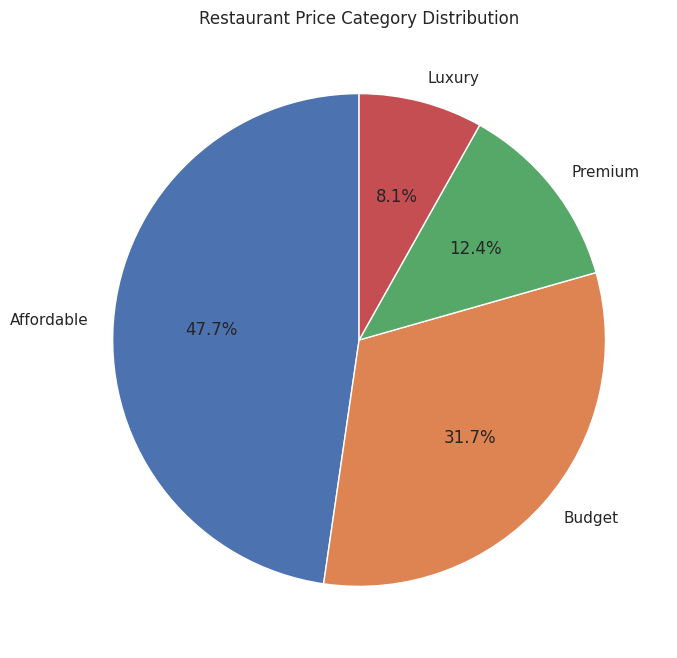

In [ ]:
price_category = pd.cut(
    df['Price'],
    bins=[0, 200, 400, 600, float('inf')],
    labels=['Budget', 'Affordable', 'Premium', 'Luxury']
)

plt.figure(figsize=(8,8))

price_category.value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Restaurant Price Category Distribution')
plt.ylabel('')
plt.show()

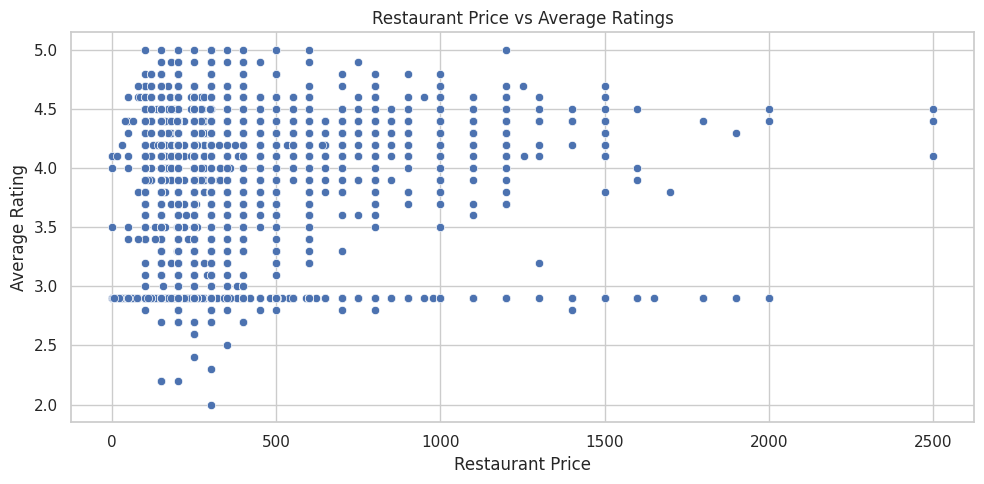

In [ ]:
plt.figure(figsize=(10,5))

sns.scatterplot(
    data=df,
    x='Price',
    y='Avg ratings'
)

plt.title('Restaurant Price vs Average Ratings')
plt.xlabel('Restaurant Price')
plt.ylabel('Average Rating')
plt.tight_layout()
plt.show()

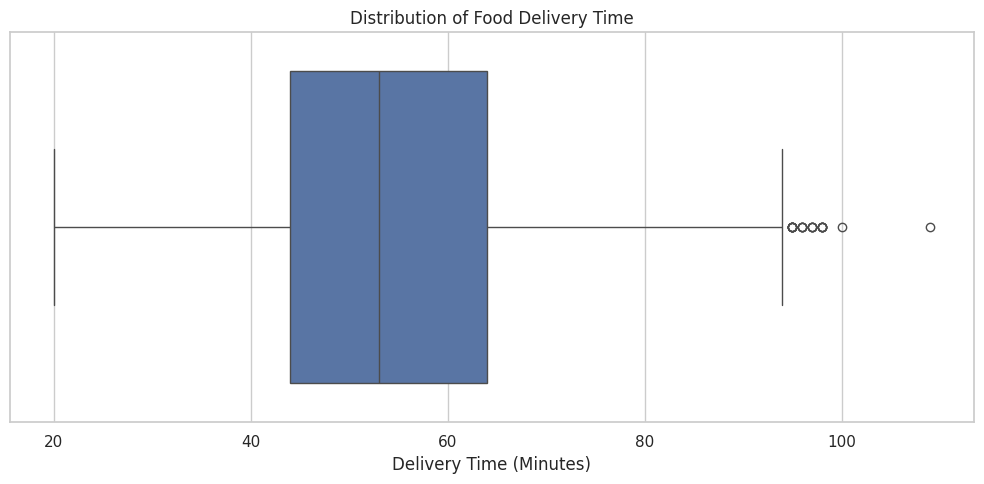

In [ ]:
plt.figure(figsize=(10,5))

sns.boxplot(x=df['Delivery time'])

plt.title('Distribution of Food Delivery Time')
plt.xlabel('Delivery Time (Minutes)')
plt.tight_layout()
plt.show()

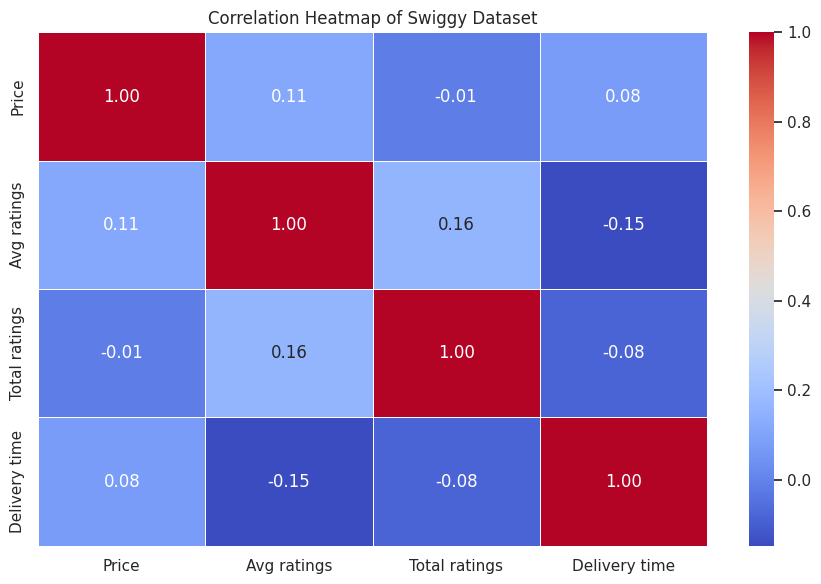

In [ ]:
plt.figure(figsize=(9,6))

correlation = df[
    ['Price', 'Avg ratings', 'Total ratings', 'Delivery time']
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    linewidths=0.5,
    fmt='.2f'
)

plt.title('Correlation Heatmap of Swiggy Dataset')
plt.tight_layout()
plt.show()

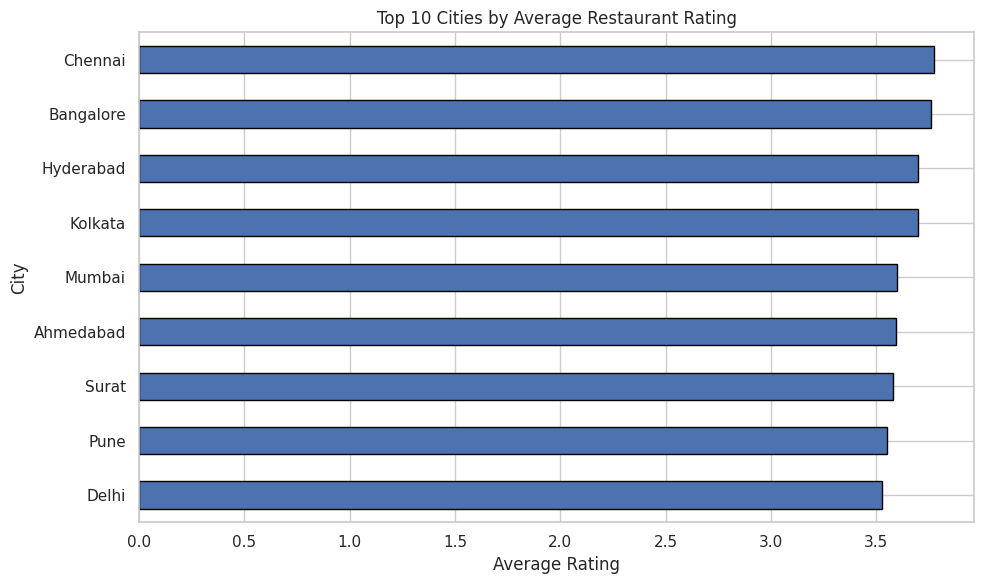

In [ ]:
plt.figure(figsize=(10,6))

city_rating = (
    df.groupby('City')['Avg ratings']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

city_rating.plot(kind='barh', edgecolor='black')

plt.title('Top 10 Cities by Average Restaurant Rating')
plt.xlabel('Average Rating')
plt.ylabel('City')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8680 entries, 0 to 8679
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             8680 non-null   int64  
 1   Area           8680 non-null   string 
 2   City           8680 non-null   string 
 3   Restaurant     8680 non-null   string 
 4   Price          8680 non-null   float64
 5   Avg ratings    8680 non-null   float64
 6   Total ratings  8680 non-null   float64
 7   Food type      8680 non-null   string 
 8   Address        8680 non-null   string 
 9   Delivery time  8680 non-null   int64  
dtypes: float64(3), int64(2), string(5)
memory usage: 678.3 KB


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Machine Learning Libraries Imported Successfully!")

Machine Learning Libraries Imported Successfully!


In [ ]:
df_ml = df.copy()

# Convert numerical columns
numeric_cols = ['Price', 'Avg ratings', 'Total ratings', 'Delivery time']

for col in numeric_cols:
    df_ml[col] = pd.to_numeric(df_ml[col], errors='coerce')

# Remove records with missing target values
df_ml = df_ml.dropna(subset=['Delivery time'])

# Remove invalid delivery times
df_ml = df_ml[df_ml['Delivery time'] > 0]

print("Dataset prepared for Machine Learning!")
print(df_ml.shape)

Dataset prepared for Machine Learning!
(8680, 10)


In [ ]:
X = df_ml[['City', 'Price', 'Avg ratings', 'Total ratings']]

y = df_ml['Delivery time']

print("Input Variables:")
print(X.head())

print("Target Variable:")
print(y.head())

Input Variables:
        City  Price  Avg ratings  Total ratings
0  Bangalore  300.0          4.4          100.0
1  Bangalore  300.0          4.1          100.0
2  Bangalore  650.0          4.4          100.0
3  Bangalore  250.0          3.9          500.0
4  Bangalore  300.0          4.0           50.0
Target Variable:
0    59
1    56
2    50
3    57
4    63
Name: Delivery time, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

Training Records: 6944
Testing Records: 1736


In [ ]:
numeric_features = ['Price', 'Avg ratings', 'Total ratings']

categorical_features = ['City']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Data preprocessing completed!")

Data preprocessing completed!


In [ ]:
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

print("Random Forest Model Created Successfully!")

Random Forest Model Created Successfully!


In [ ]:
model.fit(X_train, y_train)

print("Machine Learning Model Trained Successfully!")

Machine Learning Model Trained Successfully!


In [ ]:
y_pred = model.predict(X_test)

print("Actual Delivery Time:")
print(y_test.head(10).values)

print("Predicted Delivery Time:")
print(y_pred[:10])

Actual Delivery Time:
[66 43 67 36 58 81 63 61 64 53]
Predicted Delivery Time:
[52.63825    44.35761924 57.11882143 45.48747619 54.42227976 82.76720833
 49.71508333 54.21211111 47.66158333 51.15191071]


In [ ]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Performance")

print("MAE:", mae)

print("MSE:", mse)

print("RMSE:", rmse)

print("R2 Score:", r2)

Model Performance
MAE: 10.612560283214863
MSE: 173.6315953944889
RMSE: 13.176934218341112
R2 Score: 0.16927198479372663


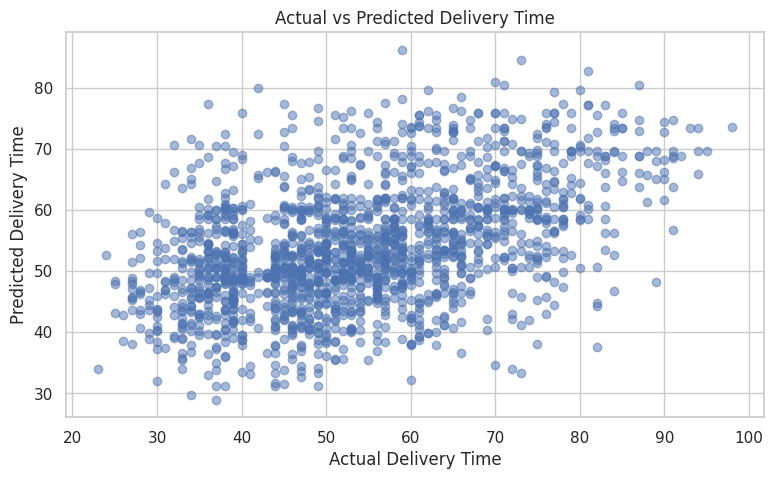

In [ ]:
plt.figure(figsize=(9,5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel('Actual Delivery Time')
plt.ylabel('Predicted Delivery Time')

plt.title('Actual vs Predicted Delivery Time')

plt.show()

In [ ]:
feature_names = model.named_steps['preprocessor'].get_feature_names_out()

importance = model.named_steps['regressor'].feature_importances_

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)

print(feature_importance)

                Feature  Importance
8     cat__City_Kolkata    0.266673
0            num__Price    0.239137
1      num__Avg ratings    0.217364
2    num__Total ratings    0.103311
5     cat__City_Chennai    0.064679
10       cat__City_Pune    0.038318
7   cat__City_Hyderabad    0.015224
3   cat__City_Ahmedabad    0.014349
6       cat__City_Delhi    0.012340
9      cat__City_Mumbai    0.010714
4   cat__City_Bangalore    0.010021
11      cat__City_Surat    0.007868


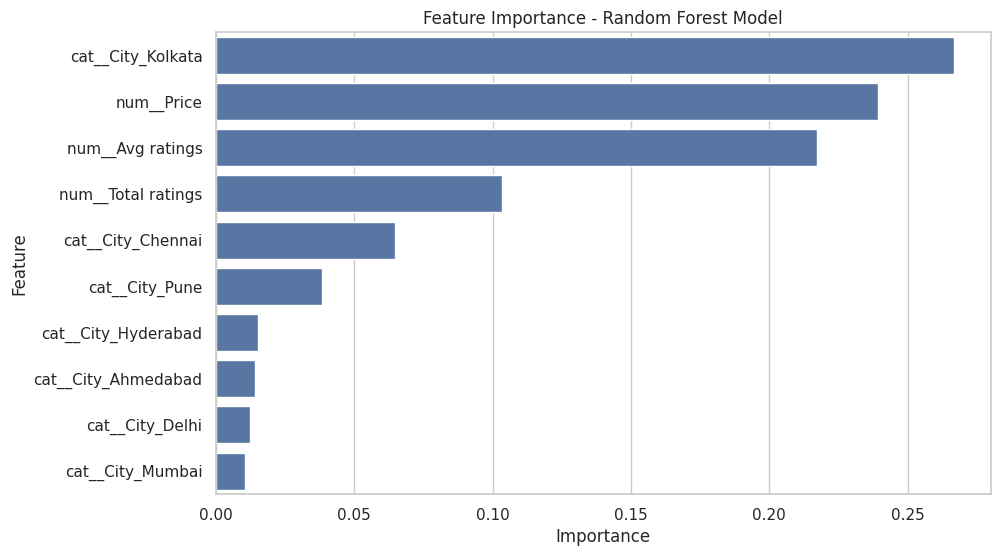

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Random Forest Model')

plt.show()

In [ ]:
new_restaurant = pd.DataFrame({
    'City': ['Bangalore'],
    'Price': [300],
    'Avg ratings': [4.4],
    'Total ratings': [100]
})

prediction = model.predict(new_restaurant)

print("Predicted Delivery Time:", round(prediction[0], 2), "minutes")

Predicted Delivery Time: 51.42 minutes


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.metrics import silhouette_score

print("All ML Libraries Imported Successfully!")

All ML Libraries Imported Successfully!


In [ ]:
df_ml = df.copy()

numeric_cols = [
    'Price',
    'Avg ratings',
    'Total ratings',
    'Delivery time'
]

for col in numeric_cols:
    df_ml[col] = pd.to_numeric(
        df_ml[col], errors='coerce'
    )

df_ml = df_ml.dropna(subset=['Delivery time'])

df_ml = df_ml[df_ml['Delivery time'] > 0]

print("ML Dataset Shape:", df_ml.shape)
df_ml.head()

ML Dataset Shape: (8680, 10)


,ID,Area,City,Restaurant,Price,Avg ratings,Total ratings,Food type,Address,Delivery time
0,211,Koramangala,Bangalore,Tandoor Hut,300.0,4.4,100.0,"Biryani,Chinese,North Indian,South Indian",5Th Block,59
1,221,Koramangala,Bangalore,Tunday Kababi,300.0,4.1,100.0,"Mughlai,Lucknowi",5Th Block,56
2,246,Jogupalya,Bangalore,Kim Lee,650.0,4.4,100.0,Chinese,Double Road,50
3,248,Indiranagar,Bangalore,New Punjabi Hotel,250.0,3.9,500.0,"North Indian,Punjabi,Tandoor,Chinese",80 Feet Road,57
4,249,Indiranagar,Bangalore,Nh8,300.0,4.0,50.0,"Rajasthani,Gujarati,North Indian,Snacks,Desser...",80 Feet Road,63


In [ ]:
X = df_ml[
    ['City', 'Price', 'Avg ratings', 'Total ratings']
]

y = df_ml['Delivery time']

print("Independent Variables:")
print(X.head())

print("Dependent Variable:")
print(y.head())

Independent Variables:
        City  Price  Avg ratings  Total ratings
0  Bangalore  300.0          4.4          100.0
1  Bangalore  300.0          4.1          100.0
2  Bangalore  650.0          4.4          100.0
3  Bangalore  250.0          3.9          500.0
4  Bangalore  300.0          4.0           50.0
Dependent Variable:
0    59
1    56
2    50
3    57
4    63
Name: Delivery time, dtype: int64


In [ ]:
linear_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# Train model
linear_model.fit(X_train, y_train)

# Make predictions
linear_pred = linear_model.predict(X_test)

In [ ]:
print("Linear Regression Performance")

print("MAE:", mean_absolute_error(y_test, linear_pred))

print("RMSE:", np.sqrt(
    mean_squared_error(y_test, linear_pred)
))

print("R2 Score:", r2_score(y_test, linear_pred))

Linear Regression Performance
MAE: 10.009276648620144
RMSE: 12.205641887251991
R2 Score: 0.2872268225974284


In [ ]:
tree_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(
        max_depth=8,
        random_state=42
    ))
])

# Train model
tree_model.fit(X_train, y_train)

# Make predictions
tree_pred = tree_model.predict(X_test)

print("Decision Tree Regression Completed!")

Decision Tree Regression Completed!


In [ ]:
print("Decision Tree Performance")

print("MAE:", mean_absolute_error(y_test, tree_pred))

print("RMSE:", np.sqrt(
    mean_squared_error(y_test, tree_pred)
))

print("R2 Score:", r2_score(y_test, tree_pred))

Decision Tree Performance
MAE: 10.220711395847594
RMSE: 12.551089802096172
R2 Score: 0.24630961510458738


In [ ]:
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

# Train model
rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)

print("Random Forest Regression Completed!")

Random Forest Regression Completed!


In [ ]:
print("Random Forest Performance")

print("MAE:", mean_absolute_error(y_test, rf_pred))

print("RMSE:", np.sqrt(
    mean_squared_error(y_test, rf_pred)
))

print("R2 Score:", r2_score(y_test, rf_pred))

Random Forest Performance
MAE: 10.612560283214863
RMSE: 13.176934218341112
R2 Score: 0.16927198479372663


In [ ]:
model_results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest'
    ],

    'MAE': [
        mean_absolute_error(y_test, linear_pred),
        mean_absolute_error(y_test, tree_pred),
        mean_absolute_error(y_test, rf_pred)
    ],

    'RMSE': [
        np.sqrt(mean_squared_error(y_test, linear_pred)),
        np.sqrt(mean_squared_error(y_test, tree_pred)),
        np.sqrt(mean_squared_error(y_test, rf_pred))
    ],

    'R2 Score': [
        r2_score(y_test, linear_pred),
        r2_score(y_test, tree_pred),
        r2_score(y_test, rf_pred)
    ]
})

print(model_results)

               Model        MAE       RMSE  R2 Score
0  Linear Regression  10.009277  12.205642  0.287227
1      Decision Tree  10.220711  12.551090  0.246310
2      Random Forest  10.612560  13.176934  0.169272


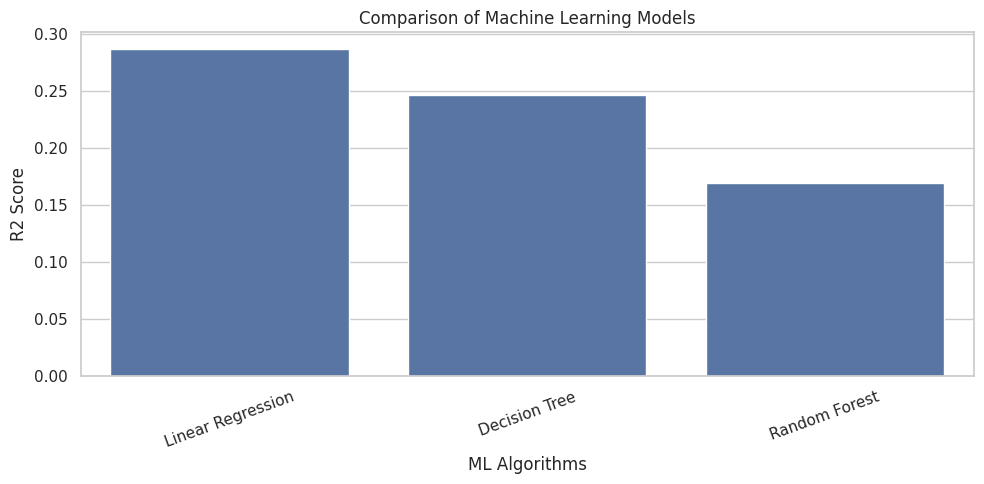

In [ ]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=model_results,
    x='Model',
    y='R2 Score'
)

plt.title('Comparison of Machine Learning Models')
plt.xlabel('ML Algorithms')
plt.ylabel('R2 Score')

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
cluster_data = df_ml[
    ['Price', 'Avg ratings', 'Total ratings', 'Delivery time']
].copy()

cluster_data = cluster_data.fillna(
    cluster_data.median()
)

print("Clustering Dataset Prepared!")
cluster_data.head()

Clustering Dataset Prepared!


,Price,Avg ratings,Total ratings,Delivery time
0,300.0,4.4,100.0,59
1,300.0,4.1,100.0,56
2,650.0,4.4,100.0,50
3,250.0,3.9,500.0,57
4,300.0,4.0,50.0,63


In [ ]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(cluster_data)

print("Data Standardized Successfully!")

Data Standardized Successfully!


In [ ]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(scaled_data)

df_ml['Restaurant Cluster'] = clusters

print("K-Means Clustering Completed!")

K-Means Clustering Completed!


In [ ]:
df_ml[
    ['Restaurant', 'Price', 'Avg ratings',
     'Total ratings', 'Delivery time',
     'Restaurant Cluster']
].head(15)

,Restaurant,Price,Avg ratings,Total ratings,Delivery time,Restaurant Cluster
0,Tandoor Hut,300.0,4.4,100.0,59,1
1,Tunday Kababi,300.0,4.1,100.0,56,1
2,Kim Lee,650.0,4.4,100.0,50,1
3,New Punjabi Hotel,250.0,3.9,500.0,57,1
4,Nh8,300.0,4.0,50.0,63,1
5,Treat,800.0,4.5,100.0,56,3
6,Chinita Real Mexican Food,1000.0,4.5,500.0,53,3
7,Cupcake Noggins - Cakespastries And Desserts,150.0,4.3,100.0,57,1
8,Tea Brew,350.0,4.1,100.0,57,1
9,Bangaliana,300.0,4.0,500.0,57,1


In [ ]:
print(
    df_ml['Restaurant Cluster'].value_counts().sort_index()
)

Restaurant Cluster
0    3537
1    4477
2      20
3     646
Name: count, dtype: int64


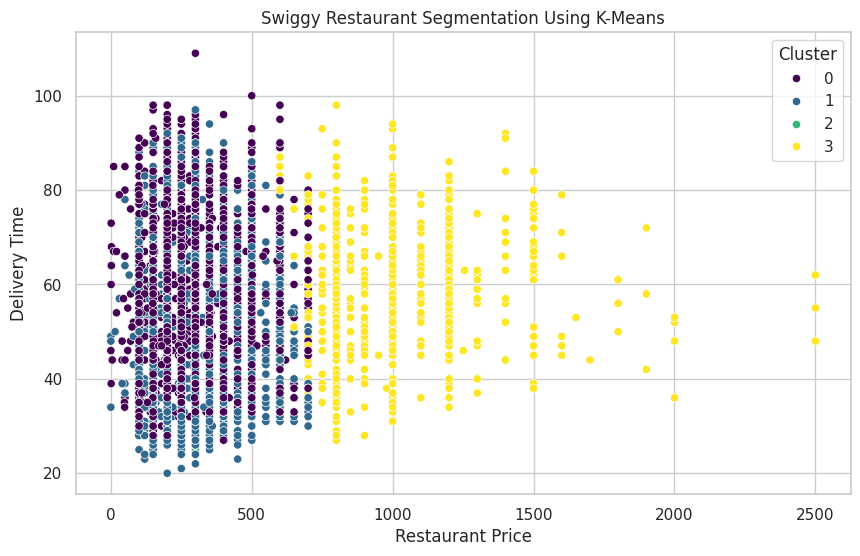

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df_ml,
    x='Price',
    y='Delivery time',
    hue='Restaurant Cluster',
    palette='viridis'
)

plt.title('Swiggy Restaurant Segmentation Using K-Means')
plt.xlabel('Restaurant Price')
plt.ylabel('Delivery Time')
plt.legend(title='Cluster')
plt.show()

In [ ]:
cluster_summary = df_ml.groupby(
    'Restaurant Cluster'
).agg({
    'Price': 'mean',
    'Avg ratings': 'mean',
    'Total ratings': 'mean',
    'Delivery time': 'mean'
}).round(2)

print(cluster_summary)

                     Price  Avg ratings  Total ratings  Delivery time
Restaurant Cluster                                                   
0                   288.70         2.95          75.20          57.08
1                   302.19         4.17         198.50          50.89
2                   317.50         4.06        6500.00          44.35
3                   996.10         3.93         115.94          58.54


In [ ]:
feature_names = rf_model.named_steps[
    'preprocessor'
].get_feature_names_out()

importance = rf_model.named_steps[
    'model'
].feature_importances_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
}).sort_values(
    by='Importance',
    ascending=False
)

print(importance_df)

                Feature  Importance
8     cat__City_Kolkata    0.266673
0            num__Price    0.239137
1      num__Avg ratings    0.217364
2    num__Total ratings    0.103311
5     cat__City_Chennai    0.064679
10       cat__City_Pune    0.038318
7   cat__City_Hyderabad    0.015224
3   cat__City_Ahmedabad    0.014349
6       cat__City_Delhi    0.012340
9      cat__City_Mumbai    0.010714
4   cat__City_Bangalore    0.010021
11      cat__City_Surat    0.007868


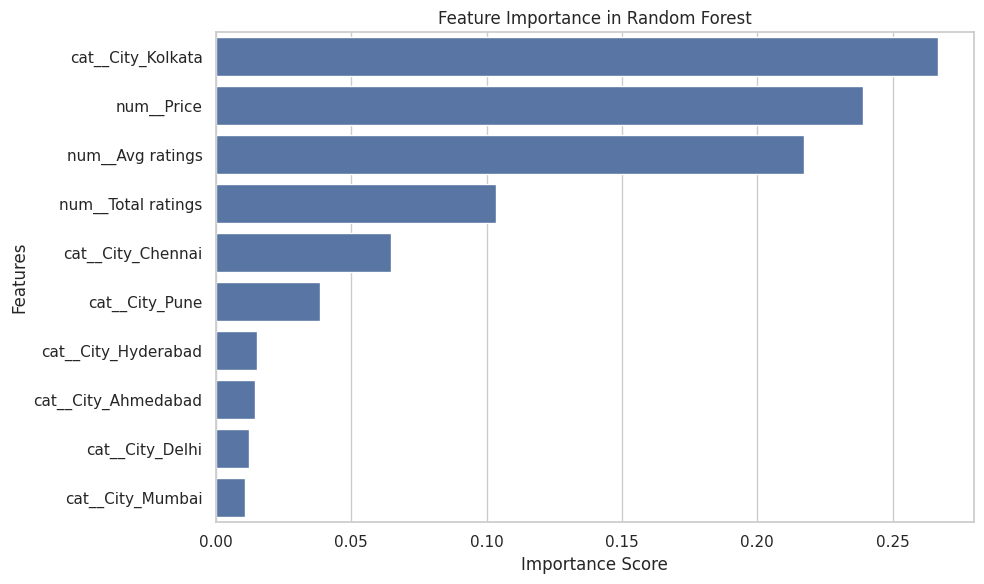

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=importance_df.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance in Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [ ]:
new_restaurant = pd.DataFrame({
    'City': ['Bangalore'],
    'Price': [300],
    'Avg ratings': [4.4],
    'Total ratings': [100]
})

print("Linear Regression Prediction:",
      linear_model.predict(new_restaurant)[0])

print("Decision Tree Prediction:",
      tree_model.predict(new_restaurant)[0])

print("Random Forest Prediction:",
      rf_model.predict(new_restaurant)[0])

Linear Regression Prediction: 47.62798082019068
Decision Tree Prediction: 49.04593639575972
Random Forest Prediction: 51.41570634920636


In [ ]:
model_results.to_csv(
    'Swiggy_ML_Model_Comparison.csv',
    index=False
)

df_ml.to_csv(
    'Swiggy_ML_Clustered_Dataset.csv',
    index=False
)

print("ML Results Saved Successfully!")

ML Results Saved Successfully!
